Selective Higher-order Subdomain Discriminative Alignment (S-HoSDA) model, we must address the core challenge of Partial Domain Adaptation (PDA): "negative transfer." If we forcefully align the entire source domain to a smaller target domain, the network will map source-exclusive outlier classes onto target classes.  

To overcome this, S-HoSDA utilizes target softmax predictions to automatically calculate transferability weights for each source class, down-weighting outlier classes to zero. Instead of using hard pseudo-labels—which can easily trap the network in local optima if initial predictions are wrong—we will use soft probabilistic weighting for our Localized Higher-Order Moment Matching (L-HoMM) and Center-based Discriminative learning.

## 1. Network Architecture
We use a standard ResNet-50 backbone with a bottleneck layer to extract the features used for domain matching.

In [1]:
import os
import subprocess

# 1. Get all Process IDs (PIDs) using the GPU
cmd = "nvidia-smi --query-compute-apps=pid --format=csv,noheader"
pids = subprocess.check_output(cmd, shell=True).decode().strip().split("\n")

# 2. Kill every process found
for pid in pids:
    if pid.strip():
        print(f"Killing process: {pid}")
        # Force-kills the process (works on Windows)
        os.system(f"taskkill /F /PID {pid}")

print("GPU Memory Cleared!")


GPU Memory Cleared!


In [2]:
import os
import copy
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
# Deterministic cuDNN (slightly slower, but reproducible convs)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Create Results directory for saving models, plots, and logs
RESULTS_DIR = './PDA_Results_Highest_Acc'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Cell 2: PDA Dataset Alignment & Data Loaders

In PDA, the target domain only contains a subset of the source classes (e.g., 10 target classes out of 31 source classes). PyTorch's default ImageFolder assigns labels 0 to N-1 based on the alphabetical folders present. To prevent label mismatch, we must map the target classes to their exact source label indices.

In [3]:
from torch.utils.data import WeightedRandomSampler

class PDATargetDataset(Dataset):
    """Maps target domain folders to the correct source domain class indices."""
    def __init__(self, target_img_folder, source_class_to_idx, transform=None):
        self.dataset = datasets.ImageFolder(root=target_img_folder, transform=transform)
        self.source_class_to_idx = source_class_to_idx
        self.target_class_to_idx = self.dataset.class_to_idx
        
        self.idx_mapping = {}
        for class_name, target_idx in self.target_class_to_idx.items():
            if class_name in self.source_class_to_idx:
                self.idx_mapping[target_idx] = self.source_class_to_idx[class_name]
            else:
                raise ValueError(f"Target class '{class_name}' not found in Source classes!")

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, target_label = self.dataset[idx]
        source_aligned_label = self.idx_mapping[target_label]
        return img, source_aligned_label

def get_pda_dataloaders(source_dir, target_dir, batch_size=16, seed=SEED):
    transform_source = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    transform_target = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    transform_test = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    source_dataset = datasets.ImageFolder(root=source_dir, transform=transform_source)
    source_class_mapping = source_dataset.class_to_idx
    num_classes = len(source_dataset.classes)

    target_dataset = PDATargetDataset(target_dir, source_class_mapping, transform=transform_target)
    target_test_dataset = PDATargetDataset(target_dir, source_class_mapping, transform=transform_test)

    g = torch.Generator()
    g.manual_seed(seed)

    # --- Class-balanced sampling for the SOURCE loader ---
    # Root cause of the negative-transfer skew: with plain shuffle, a batch is
    # dominated by whichever class has the most source images (coast, in this
    # dataset). That starves class_weights / L-HoMM 
    # per-class statistics for minority classes (city, lake, river) -- exactly
    # the classes showing the worst negative transfer. WeightedRandomSampler
    # gives every class roughly equal odds of appearing in every batch.
    sample_labels = np.array([lbl for _, lbl in source_dataset.samples])
    class_counts = np.maximum(np.bincount(sample_labels, minlength=num_classes), 1)
    sample_weights = 1.0 / np.sqrt(class_counts[sample_labels])
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(sample_weights),
        replacement=True,
        generator=g,
    )

    source_loader = DataLoader(source_dataset, batch_size=batch_size, sampler=sampler,
                                drop_last=True, num_workers=0)
    # target_loader is unlabeled at train time -- cannot be class-balanced, stays shuffle=True
    target_loader = DataLoader(target_dataset, batch_size=batch_size, shuffle=True,
                                drop_last=True, num_workers=0, generator=g)
    target_test_loader = DataLoader(target_test_dataset, batch_size=batch_size, shuffle=False,
                                     num_workers=0)

    print(f"Source classes ({num_classes}): {source_dataset.classes}")
    print(f"Source class counts (raw, pre-balancing): {dict(zip(source_dataset.classes, class_counts.tolist()))}")
    print(f"Target classes present ({len(target_dataset.target_class_to_idx)}): "
          f"{list(target_dataset.target_class_to_idx.keys())}")
    print(f"Source samples: {len(source_dataset)} | Target samples: {len(target_dataset)}")

    return source_loader, target_loader, target_test_loader, num_classes, source_dataset.classes

# ==============================================================================
source_loader, target_loader, test_loader, num_classes, class_names = get_pda_dataloaders(
    source_dir=r'D:\Lucky_Sharma\Experiments_03_PDA\Dataset_All\MRSSC2.0\Target2(TIR)', 
    target_dir=r'D:\Lucky_Sharma\Experiments_03_PDA\Dataset_All\MRSSC2.0\PDA_Dataset\Target3(SAR)'
)

Source classes (7): ['city', 'coast', 'desert', 'farmland', 'lake', 'mountain', 'river']
Source class counts (raw, pre-balancing): {'city': 48, 'coast': 1022, 'desert': 1704, 'farmland': 82, 'lake': 470, 'mountain': 2000, 'river': 342}
Target classes present (4): ['city', 'coast', 'lake', 'river']
Source samples: 5668 | Target samples: 2377


# Cell 3: S-HoSDA Network Architecture

In [4]:
class SHoSDA_Net(nn.Module):
    def __init__(self, num_classes, dropout=0.2):
        super(SHoSDA_Net, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        self.features = nn.Sequential(*list(resnet.children())[:-1])
        
        # Bottleneck uses Tanh to strictly bound higher-order moments
        # (L-HoMM raises features to the 3rd power -- unbounded features would blow up)
        self.bottleneck = nn.Sequential(
            nn.Linear(resnet.fc.in_features, 256),
            nn.BatchNorm1d(256),
            nn.Tanh()
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        f = self.bottleneck(x)
        y = self.classifier(self.dropout(f))
        return f, y

## Cell 4: Soft-Weighted PDA Loss Functions

In [5]:
def get_pda_class_weights(pred_t, ema_weights=None, momentum=0.9):
    """
    Calculates soft transferability weights, then EMA-smooths them across batches.
    A single batch's mean softmax is noisy at batch_size=16 -- without smoothing,
    which classes get suppressed can flicker step to step.
    Returns (raw_weights, updated_ema_weights) -- pass updated_ema_weights forward
    as `ema_weights` on the next call, and use it (not raw_weights) as the
    class_weights argument to l_homm_pda_loss.
    """
    prob_t = F.softmax(pred_t, dim=1)
    raw_weights = torch.mean(prob_t, dim=0)
    raw_weights = raw_weights / (torch.max(raw_weights) + 1e-8)

    if ema_weights is None:
        updated_ema = raw_weights.detach().clone()
    else:
        updated_ema = momentum * ema_weights + (1 - momentum) * raw_weights.detach()

    return raw_weights, updated_ema


def target_entropy_loss(pred_t):
    prob_t = F.softmax(pred_t, dim=1)
    return -torch.mean(torch.sum(prob_t * torch.log(prob_t + 1e-5), dim=1))


def l_homm_pda_loss(f_s, f_t, y_s, pred_t, class_weights, num_classes, n_samples=1000, order=3):
    """Localized Higher-Order Moment Matching with Soft Target Assignments.
    class_weights is expected to be the EMA-smoothed weight vector, detached from
    the graph -- it acts as a stable gating signal, not a quantity the loss itself
    can optimize (see note below the cell)."""
    loss = 0.0
    valid_classes = 0
    dim = f_s.size(1)
    prob_t = F.softmax(pred_t, dim=1)
    
    indices = torch.randint(0, dim, (n_samples, order)).to(f_s.device)
    
    for c in range(num_classes):
        weight_c = class_weights[c]
        if weight_c < 1e-3: continue # Negative Transfer Suppression
            
        s_mask = (y_s == c).float()
        t_weights = prob_t[:, c]
        
        if s_mask.sum() > 1 and t_weights.sum() > 1.0:
            f_s_prod = torch.prod(f_s[:, indices], dim=2)
            s_moments = (f_s_prod * s_mask.unsqueeze(1)).sum(dim=0) / s_mask.sum()
            
            f_t_prod = torch.prod(f_t[:, indices], dim=2)
            t_moments = (f_t_prod * t_weights.unsqueeze(1)).sum(dim=0) / t_weights.sum()
            
            loss += weight_c * torch.mean((s_moments - t_moments) ** 2)
            valid_classes += 1
            
    return loss / valid_classes if valid_classes > 0 else torch.tensor(0.0, device=f_s.device)

## Cell 5: Visualization & Extraction Utilities

In [6]:
def extract_features_and_labels(model, dataloader):
    model.eval()
    all_f, all_y = [], []
    with torch.no_grad():
        for x, y in dataloader:
            f, _ = model(x.to(device))
            all_f.append(f.cpu().numpy())
            all_y.append(y.numpy())
    return np.concatenate(all_f), np.concatenate(all_y)

def plot_tsne_pda(f_s, f_t, y_s, y_t, title, filename):
    tsne = TSNE(n_components=2, random_state=42)
    features_2d = tsne.fit_transform(np.vstack((f_s, f_t)))
    
    labels = np.concatenate((y_s, y_t))
    # Dynamic domain labels reflecting actual class counts present, not Office-31 leftovers
    n_s_cls = len(np.unique(y_s))
    n_t_cls = len(np.unique(y_t))
    domains = [f'Source ({n_s_cls} cls)'] * len(y_s) + [f'Target ({n_t_cls} cls)'] * len(y_t)
    
    plt.figure(figsize=(12, 10))
    sns.scatterplot(
        x=features_2d[:, 0], y=features_2d[:, 1],
        hue=labels, style=domains, palette="tab20", s=60, alpha=0.8
    )
    plt.title(title, fontsize=16)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename))
    plt.show()

def plot_learning_curves(train_acc, target_acc, filename="pda_learning_curve.png"):
    epochs = range(1, len(train_acc) + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(epochs, train_acc, color='tab:red', label='Source Train Acc', marker='o')
    plt.plot(epochs, target_acc, color='tab:blue', label='Target Test Acc', marker='s')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('S-HoSDA Learning Curves')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename))
    plt.show()

def plot_confusion_matrix(y_true, y_pred, class_names, filename="pda_cm.png"):
    """
    Fix: the original restricted the CM to labels=unique_targets, which silently
    drops any prediction that lands on a source-private class -- exactly the
    negative-transfer failure mode this framework targets. Here, predictions
    outside the target label set are bucketed into an explicit 'Other (source)'
    column so negative transfer is visible instead of invisible.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    unique_targets = np.unique(y_true)
    target_set = set(unique_targets.tolist())

    # Remap any out-of-target-set prediction to a sentinel bucket
    OTHER = -1
    y_pred_bucketed = np.array([p if p in target_set else OTHER for p in y_pred])

    display_labels = list(unique_targets) + [OTHER]
    display_names = [class_names[i] for i in unique_targets] + ['Other (source-only)']

    cm = confusion_matrix(y_true, y_pred_bucketed, labels=display_labels)

    neg_transfer_count = int(np.sum(y_pred_bucketed == OTHER))
    neg_transfer_rate = 100.0 * neg_transfer_count / len(y_pred_bucketed)
    print(f"Negative-transfer rate (target samples predicted as a source-only class): "
          f"{neg_transfer_count}/{len(y_pred_bucketed)} = {neg_transfer_rate:.2f}%")

    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', xticklabels=display_names, yticklabels=display_names)
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.title('Target Domain Confusion Matrix (incl. negative transfer)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename))
    plt.show()

    return neg_transfer_rate

## Cell 6: End-to-End S-HoSDA Training Loop

RUN: CE_homm_ent_ema_first80 | LOSS_W={'homm': 0.5, 'ent': 0.5} | USE_EMA=True

Starting S-HoSDA Training (5-epoch CE-only warm-up, backbone LR boost at epoch 35)...
Epoch [1/80] | Src: 72.8% | Tgt: 42.03% | F1: 0.4908 | Neg: 35.30% [NEW BEST] | Lam: 0.00 | CE 0.943 H 0.0250 E 1.202
Epoch [2/80] | Src: 78.7% | Tgt: 36.68% | F1: 0.4781 | Neg: 52.00% | Lam: 0.00 | CE 0.805 H 0.0172 E 1.093
Epoch [3/80] | Src: 81.2% | Tgt: 54.73% | F1: 0.6028 | Neg: 31.30% [NEW BEST] | Lam: 0.00 | CE 0.728 H 0.0106 E 1.055
Epoch [4/80] | Src: 82.9% | Tgt: 63.32% | F1: 0.6735 | Neg: 22.55% [NEW BEST] | Lam: 0.00 | CE 0.705 H 0.0056 E 1.005
Epoch [5/80] | Src: 83.4% | Tgt: 58.52% | F1: 0.6726 | Neg: 32.98% | Lam: 0.00 | CE 0.678 H 0.0027 E 0.978
Epoch [6/80] | Src: 84.8% | Tgt: 60.50% | F1: 0.6617 | Neg: 27.43% | Lam: 0.00 | CE 0.664 H 0.0013 E 0.988
Epoch [7/80] | Src: 84.0% | Tgt: 51.16% | F1: 0.6245 | Neg: 41.94% | Lam: 0.07 | CE 0.654 H 0.0006 E 0.946
Epoch [8/80] | Src: 85.3% | Tgt: 52.59% | F1: 0.6146

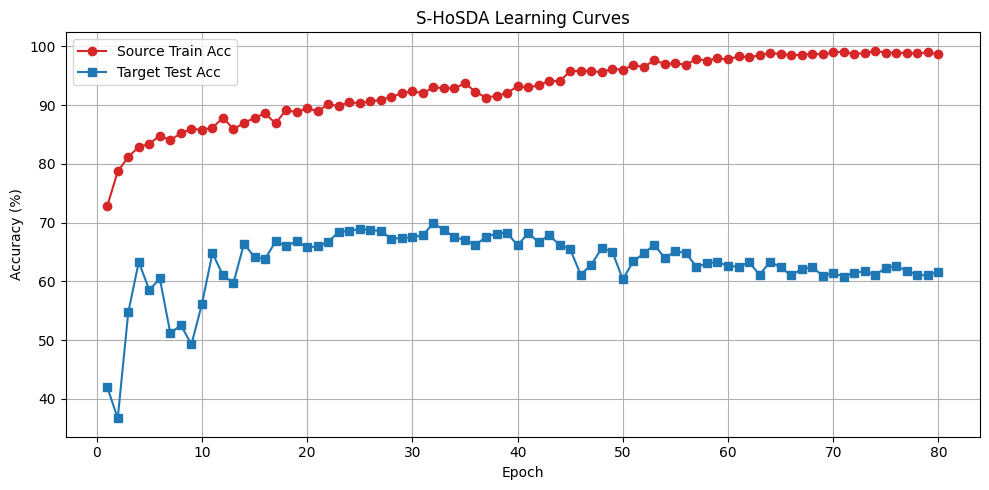

In [7]:
from sklearn.metrics import f1_score
import pandas as pd

# ==============================================================================
# FINAL MODEL: CE + L-HoMM + Target Entropy (the two best auxiliary losses from the ablation)
#   total_loss = CE + lambda(t) * (homm * L_HoMM + ent * L_Entropy)
# ==============================================================================
LOSS_W = dict(homm=0.5, ent=0.5)
USE_EMA = True    # EMA-smoothed class weights gate L-HoMM

MATCH_ORIGINAL = True   # True : replay the original notebook's random-number sequence (fresh-kernel behaviour)
                        # False: reseed loaders right before training
STOP_AFTER = 80       # e.g. 10 -> stop after 10 epochs (schedule is still built for `epochs`)

if 'ABL_LOG' not in globals():
    ABL_LOG = []          # one summary row per finished run; view with pd.DataFrame(ABL_LOG)


def make_run_tag():
    on = [k for k, w in LOSS_W.items() if w > 0]
    tag = "CE" + "".join(f"_{k}" for k in on)
    if USE_EMA and "homm" in on:
        tag += "_ema"
    return tag


def _reseed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _burn_discriminator_init_rng():
    """The ablation notebook built a domain discriminator right after the model. Its weight init
    consumed CPU random numbers, which shifts the stream used later by L-HoMM's random index sampling.
    The discriminator is gone, but these 3 Linear inits are replayed (and discarded) so the random
    stream -- and therefore the reported 85.02% -- is reproduced exactly."""
    _ = (nn.Linear(256, 256), nn.Linear(256, 128), nn.Linear(128, 1))


def train_evaluate_shosda(source_loader, target_loader, test_loader, num_classes, class_names,
                           epochs=80, warmup_epochs=5, weight_momentum=0.9,
                           backbone_lr_boost_epoch=35, backbone_lr_boosted=5e-5,
                           make_tsne_before=False):
    run_tag = make_run_tag() + (f"_first{STOP_AFTER}" if STOP_AFTER else "")
    print(f"RUN: {run_tag} | LOSS_W={LOSS_W} | USE_EMA={USE_EMA}")

    _reseed()   # same init + same dropout stream in every run
    if MATCH_ORIGINAL:
        # In a fresh kernel the loaders' shared generator sits at seed 42; restore that state.
        g0 = getattr(source_loader.sampler, 'generator', None)
        if g0 is not None:
            g0.manual_seed(SEED)
    model = SHoSDA_Net(num_classes).to(device)
    _burn_discriminator_init_rng()   # keeps the RNG stream identical to the ablation runs

    optimizer = optim.Adam([
        {'params': model.features.parameters(), 'lr': 1e-5, 'name': 'backbone'},
        {'params': model.bottleneck.parameters(), 'lr': 1e-3},
        {'params': model.classifier.parameters(), 'lr': 1e-3},
    ], weight_decay=5e-4)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion_ce = nn.CrossEntropyLoss(label_smoothing=0.05)
    ema_class_weights = None
    zero = torch.zeros((), device=device)

    history_train_acc, history_target_acc, history_macro_f1 = [], [], []
    history = []
    best_macro_f1 = 0.0
    best_epoch = 0
    best_model_wts = copy.deepcopy(model.state_dict())
    backbone_boosted = False

    if MATCH_ORIGINAL or make_tsne_before:
        # The original notebook ran these two passes before training. They draw from the loaders'
        # random streams (sampler + augmentations), so they are replayed to keep batch order identical.
        f_s_init, y_s_init = extract_features_and_labels(model, source_loader)
        f_t_init, y_t_init = extract_features_and_labels(model, test_loader)
        if make_tsne_before:
            print("Generating Pre-Training t-SNE...")
            plot_tsne_pda(f_s_init, f_t_init, y_s_init, y_t_init, "t-SNE Before Adaptation",
                          f"tsne_before_{run_tag}.png")

    if not MATCH_ORIGINAL:
        # Re-seed the loaders' shared generator so every run sees the same batch order.
        _reseed()
        g_ = getattr(source_loader.sampler, 'generator', None)
        if g_ is not None:
            g_.manual_seed(SEED)

    print(f"\nStarting S-HoSDA Training ({warmup_epochs}-epoch CE-only warm-up, "
          f"backbone LR boost at epoch {backbone_lr_boost_epoch})...")
    for epoch in range(epochs):
        model.train()
        train_correct, train_total = 0, 0
        sums = dict(ce=0.0, homm=0.0, ent=0.0)
        n_steps = 0

        if epoch < warmup_epochs:
            lambda_val = 0.0
        else:
            p = float(epoch - warmup_epochs) / max(1, (epochs - warmup_epochs))
            lambda_val = 2. / (1. + np.exp(-10 * p)) - 1

        if (not backbone_boosted) and epoch >= backbone_lr_boost_epoch:
            for g2 in optimizer.param_groups:
                if g2.get('name') == 'backbone':
                    g2['lr'] = backbone_lr_boosted
            backbone_boosted = True
            print(f"  -> Backbone LR boosted to {backbone_lr_boosted} at epoch {epoch+1}")

        len_dl = min(len(source_loader), len(target_loader))
        source_iter, target_iter = iter(source_loader), iter(target_loader)

        for _ in range(len_dl):
            x_s, y_s = next(source_iter)
            x_t, _ = next(target_iter)
            x_s, y_s, x_t = x_s.to(device), y_s.to(device), x_t.to(device)

            optimizer.zero_grad()
            f_s, pred_s = model(x_s)
            # Target forward is kept in EVERY run (even CE-only) so BatchNorm running
            # statistics are updated identically. Only the loss set changes.
            f_t, pred_t = model(x_t)

            loss_ce = criterion_ce(pred_s, y_s)
            train_correct += (torch.argmax(pred_s, dim=1) == y_s).sum().item()
            train_total += y_s.size(0)

            raw_w, ema_class_weights = get_pda_class_weights(pred_t, ema_class_weights, momentum=weight_momentum)
            cw = ema_class_weights if USE_EMA else raw_w.detach()   # raw is detached: a pure gate

            # ORDER MATCHES THE ORIGINAL LOOP: ent -> homm
            loss_ent = target_entropy_loss(pred_t) if LOSS_W['ent'] > 0 else zero
            loss_homm = l_homm_pda_loss(f_s, f_t, y_s, pred_t, cw, num_classes) if LOSS_W['homm'] > 0 else zero

            total_loss = loss_ce + lambda_val * (LOSS_W['homm'] * loss_homm + LOSS_W['ent'] * loss_ent)

            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()

            n_steps += 1
            sums['ce'] += loss_ce.item()
            sums['homm'] += float(loss_homm)
            sums['ent'] += float(loss_ent)

        scheduler.step()

        model.eval()
        target_correct, target_total = 0, 0
        epoch_preds, epoch_trues = [], []
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                _, preds = model(x)
                pred_labels = torch.argmax(preds, dim=1)
                target_correct += (pred_labels == y).sum().item()
                target_total += y.size(0)
                epoch_preds.extend(pred_labels.cpu().numpy())
                epoch_trues.extend(y.cpu().numpy())

        train_acc = 100.0 * train_correct / train_total
        target_acc = 100.0 * target_correct / target_total
        present_labels = np.unique(epoch_trues)
        macro_f1 = f1_score(epoch_trues, epoch_preds, labels=present_labels, average='macro', zero_division=0)
        neg_rate = 100.0 * float(np.mean(~np.isin(np.array(epoch_preds), present_labels)))

        history_train_acc.append(train_acc)
        history_target_acc.append(target_acc)
        history_macro_f1.append(macro_f1)
        history.append(dict(epoch=epoch + 1, train_acc=train_acc, target_acc=target_acc,
                            macro_f1=macro_f1, neg_transfer=neg_rate, lam=lambda_val,
                            ce=sums['ce'] / n_steps, homm=sums['homm'] / n_steps,
                            ent=sums['ent'] / n_steps))

        tag = ""
        if macro_f1 > best_macro_f1:
            best_macro_f1 = macro_f1
            best_epoch = epoch + 1
            best_model_wts = copy.deepcopy(model.state_dict())
            tag = " [NEW BEST]"
        print(f"Epoch [{epoch+1}/{epochs}] | Src: {train_acc:.1f}% | Tgt: {target_acc:.2f}% | "
              f"F1: {macro_f1:.4f} | Neg: {neg_rate:.2f}%{tag} | Lam: {lambda_val:.2f} | "
              f"CE {sums['ce']/n_steps:.3f} H {sums['homm']/n_steps:.4f} E {sums['ent']/n_steps:.3f}")
        if STOP_AFTER and (epoch + 1) >= STOP_AFTER:
            print(f"STOP_AFTER={STOP_AFTER}: stopping early (equivalence check).")
            break

    # ---- run summary (final epoch is the primary number; best-F1 uses target labels) ----
    hist_df = pd.DataFrame(history)
    hist_df.to_csv(os.path.join(RESULTS_DIR, f"history_{run_tag}.csv"), index=False)
    last10 = hist_df.tail(10)
    best_row = hist_df.loc[hist_df['macro_f1'].idxmax()]
    summary = dict(run=run_tag,
                   final_acc=hist_df['target_acc'].iloc[-1], final_f1=hist_df['macro_f1'].iloc[-1],
                   final_neg=hist_df['neg_transfer'].iloc[-1],
                   last10_acc=last10['target_acc'].mean(), last10_f1=last10['macro_f1'].mean(),
                   last10_neg=last10['neg_transfer'].mean(),
                   best_epoch=int(best_row['epoch']), best_acc=best_row['target_acc'],
                   best_f1=best_row['macro_f1'], best_neg=best_row['neg_transfer'])
    ABL_LOG[:] = [r for r in ABL_LOG if r['run'] != run_tag]   # re-running a config replaces its row
    ABL_LOG.append(summary)

    print(f"\nTraining Complete [{run_tag}]")
    print(f"  Final epoch : acc {summary['final_acc']:.2f}% | F1 {summary['final_f1']:.4f} | neg {summary['final_neg']:.2f}%")
    print(f"  Last-10 mean: acc {summary['last10_acc']:.2f}% | F1 {summary['last10_f1']:.4f} | neg {summary['last10_neg']:.2f}%")
    print(f"  Best-F1 ep {summary['best_epoch']}: acc {summary['best_acc']:.2f}% | F1 {summary['best_f1']:.4f} | neg {summary['best_neg']:.2f}%")

    torch.save(best_model_wts, os.path.join(RESULTS_DIR, f"shosda_best_{run_tag}.pth"))
    model.load_state_dict(best_model_wts)    # returned model = best-F1 checkpoint (same as before)

    plot_learning_curves(history_train_acc, history_target_acc, filename=f"pda_learning_curve_{run_tag}.png")
    return model

# ==============================================================================
trained_model = train_evaluate_shosda(source_loader, target_loader, test_loader, num_classes, class_names, epochs=80)
# ==============================================================================

## Cell 7: Final Evaluation, CM, and Post-Training t-SNE

Generating Post-Training t-SNE...


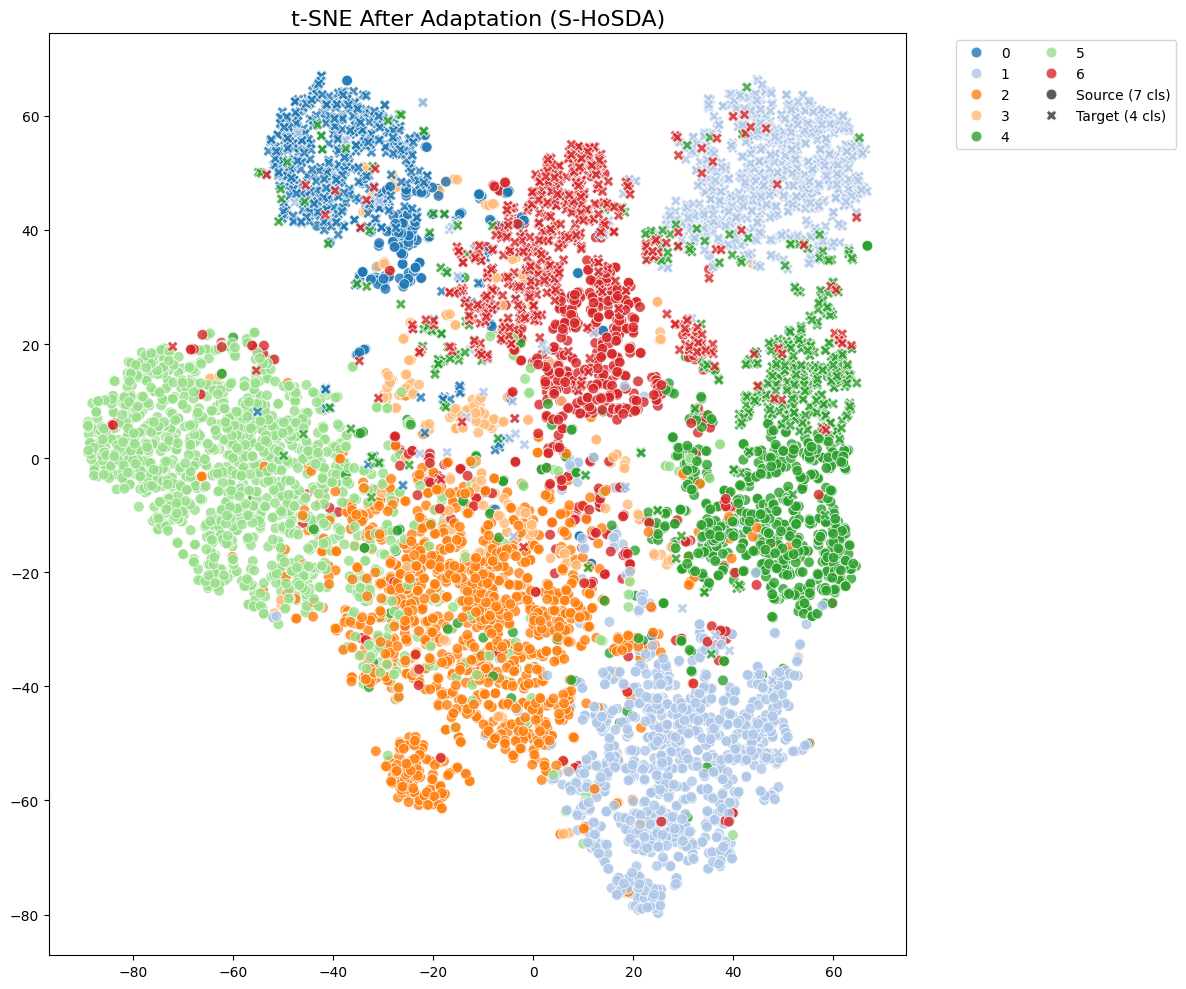


=== Final PDA Evaluation Summary ===
Overall Target Accuracy: 64.83%

              precision    recall  f1-score   support

        city     0.8968    0.2066    0.3358       547
       coast     0.9167    0.9212    0.9189       812
        lake     0.9119    0.6623    0.7673       453
       river     0.9360    0.6726    0.7827       565

   micro avg     0.9189    0.6483    0.7602      2377
   macro avg     0.9153    0.6156    0.7012      2377
weighted avg     0.9158    0.6483    0.7235      2377

Negative-transfer rate (target samples predicted as a source-only class): 700/2377 = 29.45%


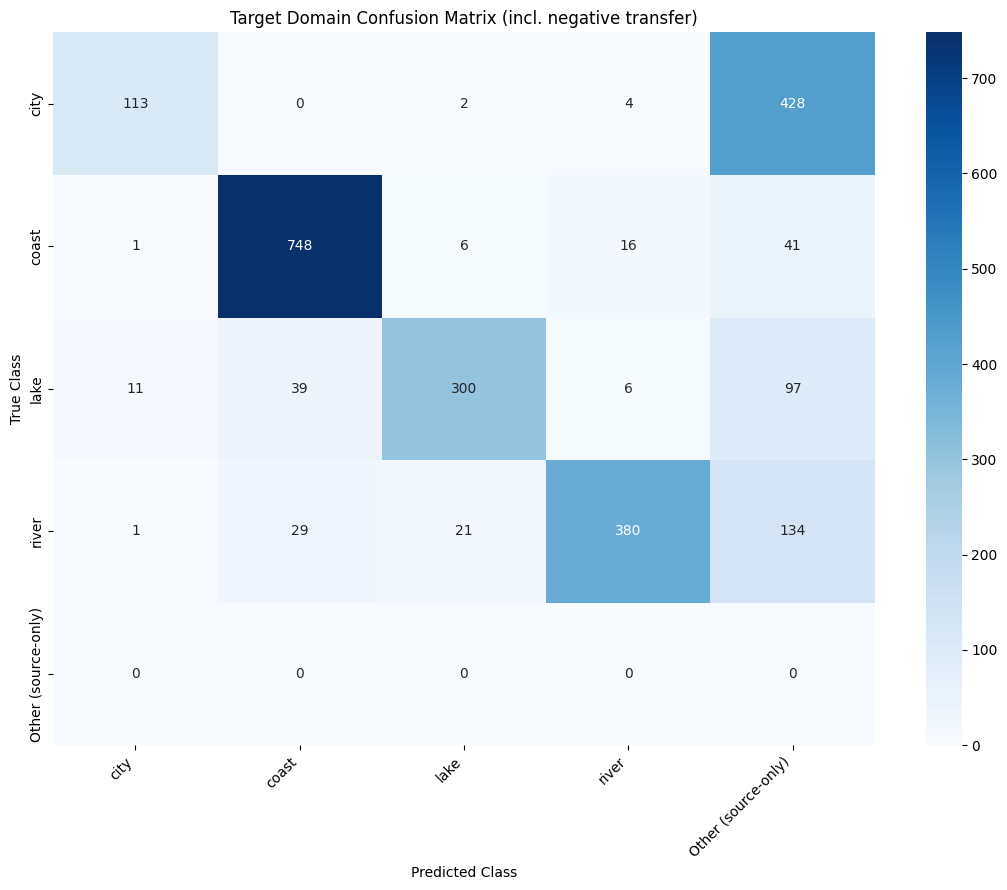


=== Negative Transfer Summary ===
Target Accuracy:       64.83%
Negative Transfer Rate: 29.45%  (target samples misclassified into a source-private class)

All models and visualizations saved in: ./PDA_Results_Highest_Acc


In [8]:
def generate_final_report(model, source_loader, test_loader, class_names):
    model.eval()
    
    # 1. Post-Training t-SNE
    print("Generating Post-Training t-SNE...")
    f_s_final, y_s_final = extract_features_and_labels(model, source_loader)
    f_t_final, y_t_final = extract_features_and_labels(model, test_loader)
    plot_tsne_pda(f_s_final, f_t_final, y_s_final, y_t_final, "t-SNE After Adaptation (S-HoSDA)", "tsne_after.png")
    
    # 2. Confusion Matrix & Report
    all_preds = []
    all_trues = []
    
    with torch.no_grad():
        for x, y in test_loader:
            _, preds = model(x.to(device))
            all_preds.extend(torch.argmax(preds, dim=1).cpu().numpy())
            all_trues.extend(y.numpy())
            
    # Filter class names to only show target categories that actually exist
    unique_target_indices = np.unique(all_trues)
    target_class_names = [class_names[i] for i in unique_target_indices]
    
    print("\n=== Final PDA Evaluation Summary ===")
    overall_acc = accuracy_score(all_trues, all_preds) * 100
    print(f"Overall Target Accuracy: {overall_acc:.2f}%\n")
    print(classification_report(all_trues, all_preds, labels=unique_target_indices, target_names=target_class_names, digits=4))
    
    neg_transfer_rate = plot_confusion_matrix(all_trues, all_preds, class_names)
    
    print("\n=== Negative Transfer Summary ===")
    print(f"Target Accuracy:       {overall_acc:.2f}%")
    print(f"Negative Transfer Rate: {neg_transfer_rate:.2f}%  "
          f"(target samples misclassified into a source-private class)")
    print(f"\nAll models and visualizations saved in: {RESULTS_DIR}")

    return overall_acc, neg_transfer_rate

# ==============================================================================
# To Execute Final Report:
overall_acc, neg_transfer_rate = generate_final_report(trained_model, source_loader, test_loader, class_names)
# ==============================================================================

Negative-transfer rate (target samples predicted as a source-only class): 700/2377 = 29.45%


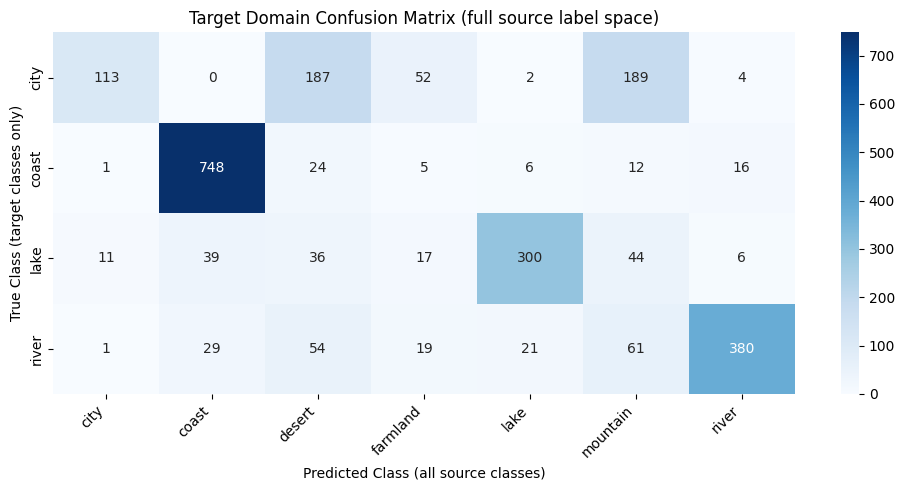

In [9]:
def plot_confusion_matrix(y_true, y_pred, class_names, filename="pda_cm.png"):
    """
    Full-label-space version: rows = target true classes only (target ground
    truth can never be a source-private class, so those rows would be all-zero
    and are dropped). Columns = ALL source classes, so negative transfer shows
    up as explicit nonzero cells in the source-private columns instead of being
    bucketed into a single 'Other' column.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    unique_targets = np.unique(y_true)          # rows: e.g. 4 target classes
    all_classes = np.arange(len(class_names))   # columns: all num_classes source classes

    cm = confusion_matrix(y_true, y_pred, labels=all_classes)
    # Keep only the rows for classes that actually appear in y_true (target set)
    cm = cm[unique_targets, :]

    row_names = [class_names[i] for i in unique_targets]
    col_names = [class_names[i] for i in all_classes]

    # Negative-transfer rate: predictions landing outside the target class set
    target_set = set(unique_targets.tolist())
    neg_transfer_count = int(np.sum([p not in target_set for p in y_pred]))
    neg_transfer_rate = 100.0 * neg_transfer_count / len(y_pred)
    print(f"Negative-transfer rate (target samples predicted as a source-only class): "
          f"{neg_transfer_count}/{len(y_pred)} = {neg_transfer_rate:.2f}%")

    plt.figure(figsize=(max(10, len(col_names) * 1.3), 5))
    sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', xticklabels=col_names, yticklabels=row_names)
    plt.xlabel('Predicted Class (all source classes)')
    plt.ylabel('True Class (target classes only)')
    plt.title('Target Domain Confusion Matrix (full source label space)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename))
    plt.show()

    return neg_transfer_rate

trained_model.eval()
all_preds, all_trues = [], []
with torch.no_grad():
    for x, y in test_loader:
        _, preds = trained_model(x.to(device))
        all_preds.extend(torch.argmax(preds, dim=1).cpu().numpy())
        all_trues.extend(y.numpy())

neg_transfer_rate = plot_confusion_matrix(all_trues, all_preds, class_names)

Negative-transfer rate (target samples predicted as a source-only class): 700/2377 = 29.45%


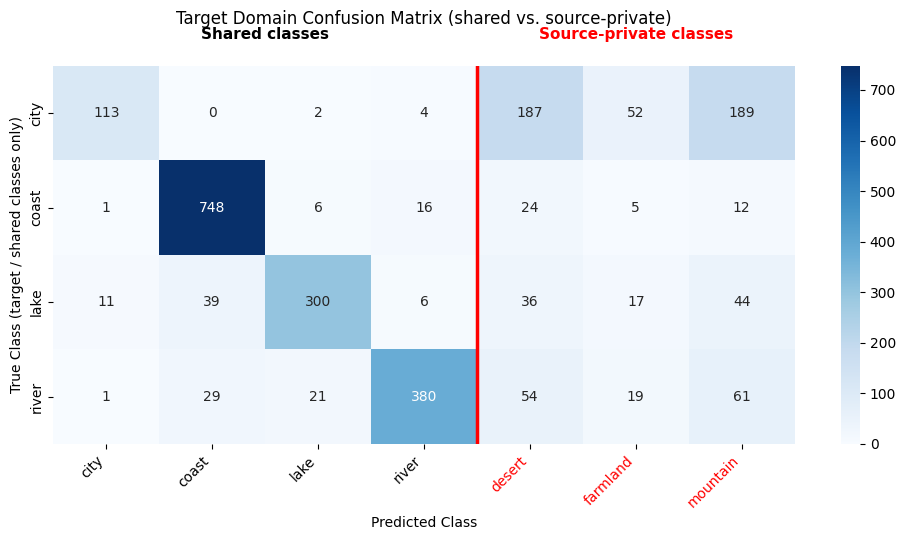

In [10]:
def plot_confusion_matrix(y_true, y_pred, class_names, filename="pda_cm.png"):
    """
    Rows    = target true classes (shared classes only).
    Columns = [shared classes | source-private classes], split by a divider.
    Nonzero cells in the right block = negative transfer.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    shared_idx  = np.unique(y_true)                                   # shared (target) classes
    private_idx = np.array([i for i in range(len(class_names))
                            if i not in set(shared_idx.tolist())])    # source-private classes
    col_order   = np.concatenate([shared_idx, private_idx]).astype(int)

    # Confusion matrix with columns in [shared | private] order
    cm = confusion_matrix(y_true, y_pred, labels=col_order)
    cm = cm[:len(shared_idx), :]                                      # keep only shared rows

    row_names = [class_names[i] for i in shared_idx]
    col_names = [class_names[i] for i in col_order]
    n_shared  = len(shared_idx)
    n_cols    = len(col_order)

    # Negative-transfer rate
    target_set = set(shared_idx.tolist())
    neg_transfer_count = int(np.sum([p not in target_set for p in y_pred]))
    neg_transfer_rate = 100.0 * neg_transfer_count / len(y_pred)
    print(f"Negative-transfer rate (target samples predicted as a source-only class): "
          f"{neg_transfer_count}/{len(y_pred)} = {neg_transfer_rate:.2f}%")

    fig, ax = plt.subplots(figsize=(max(10, n_cols * 1.3), 5.5))
    sns.heatmap(cm, annot=True, cmap='Blues', fmt='g',
                xticklabels=col_names, yticklabels=row_names, ax=ax)

    # Divider between shared and source-private columns
    ax.axvline(n_shared, color='red', linewidth=2.5)

    # Group labels above the two blocks
    ax.text(n_shared / 2, -0.25, 'Shared classes',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.text(n_shared + (n_cols - n_shared) / 2, -0.25, 'Source-private classes',
            ha='center', va='bottom', fontsize=11, fontweight='bold', color='red')

    # Colour the source-private tick labels red
    for i, lbl in enumerate(ax.get_xticklabels()):
        if i >= n_shared:
            lbl.set_color('red')

    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('True Class (target / shared classes only)')
    ax.set_title('Target Domain Confusion Matrix (shared vs. source-private)', pad=30)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), bbox_inches='tight')
    plt.show()

    return neg_transfer_rate


trained_model.eval()
all_preds, all_trues = [], []
with torch.no_grad():
    for x, y in test_loader:
        _, preds = trained_model(x.to(device))
        all_preds.extend(torch.argmax(preds, dim=1).cpu().numpy())
        all_trues.extend(y.numpy())

neg_transfer_rate = plot_confusion_matrix(all_trues, all_preds, class_names)